# 02 · Models — does a model trained before the war survive it?

Backtest produced by `python -m src.backtest` (walk-forward, every day forecast only from data available before the
12:00 CET auction on D-1). Two test windows:

* **normal** — 1 Mar 2025 – 27 Feb 2026 (control year);
* **crisis** — 28 Feb 2026 (start of the Iran war) – 13 Oct 2026 (data as of 13 Oct 2026).

Model variants: `naive` (same hour a week ago) · `ridge` / `lgbm` · `base` (calendar + TSO forecasts + price lags) vs
`gas` (+ TTF, CO₂ proxy, storage) · `static` (trained once before the window) vs `rolling` (retrained every 7 days).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.config import PROCESSED_DIR, REPORTS_DIR, FIGURES_DIR
from src import plots
from src.plots import PRE, CRISIS, THIRD, MUTED, INK_2

plots.setup()
save = lambda fig, name: fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight")
pred = pd.read_parquet(PROCESSED_DIR / "predictions.parquet")
metrics = pd.read_csv(REPORTS_DIR / "metrics.csv")
battery = pd.read_csv(REPORTS_DIR / "battery.csv")

## 1. Accuracy: normal year vs crisis (MAE, €/MWh)

In [2]:
table = metrics.pivot(index="model", columns="period", values="MAE")[["normal", "crisis"]]
table["crisis / normal"] = table["crisis"] / table["normal"]
table.sort_values("crisis").round(2)

period,normal,crisis,crisis / normal
model,,,
lgbm_gas_rolling,11.77,17.38,1.48
ridge_gas_rolling,15.00,18.98,1.27
lgbm_base_rolling,12.56,21.20,1.69
ridge_gas_static,16.13,21.39,1.33
ridge_base_rolling,15.38,25.60,1.66
ridge_base_static,15.72,29.79,1.90
lgbm_gas_static,15.58,30.94,1.99
lgbm_base_static,13.75,31.04,2.26
naive,29.21,42.92,1.47


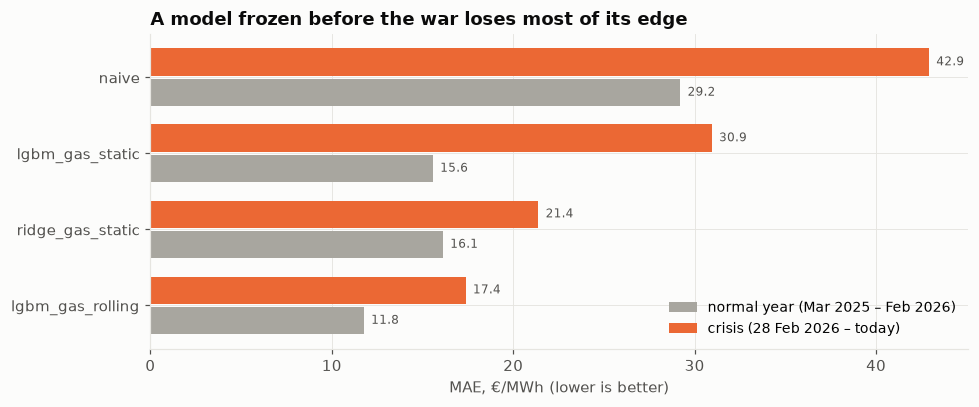

In [3]:
show = ["naive", "lgbm_gas_static", "ridge_gas_static", "lgbm_gas_rolling"]
colors = {"naive": MUTED, "lgbm_gas_static": PRE, "ridge_gas_static": THIRD, "lgbm_gas_rolling": CRISIS}
t = table.loc[show, ["normal", "crisis"]]
fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(show))
ax.barh(y + 0.2, t["normal"], height=0.36, color=MUTED, label="normal year (Mar 2025 – Feb 2026)")
ax.barh(y - 0.2, t["crisis"], height=0.36, color=CRISIS, label="crisis (28 Feb 2026 – today)")
for yi, (n, c) in enumerate(zip(t["normal"], t["crisis"])):
    ax.text(n + 0.4, yi + 0.2, f"{n:.1f}", va="center", fontsize=8, color=INK_2)
    ax.text(c + 0.4, yi - 0.2, f"{c:.1f}", va="center", fontsize=8, color=INK_2)
ax.set_yticks(y, show); ax.invert_yaxis()
ax.set_xlabel("MAE, €/MWh (lower is better)")
ax.set_title("A model frozen before the war loses most of its edge")
ax.legend(loc="lower right")
fig.tight_layout(); save(fig, "07_mae_normal_vs_crisis")

**Are the differences significant?** Diebold–Mariano test on daily losses (mean absolute error over the 24 hours of
each delivery day, Newey–West variance; `python -m src.dm_test`). p-value for "model A is more accurate than model B":

In [4]:
dm = pd.read_csv(REPORTS_DIR / "dm_test.csv")
pairs = [("lgbm_gas_rolling", "ridge_gas_rolling"), ("lgbm_gas_rolling", "lgbm_gas_static"),
         ("lgbm_gas_rolling", "lgbm_base_rolling"), ("lgbm_gas_static", "lgbm_base_static"),
         ("lgbm_base_static", "lgbm_gas_static"), ("ridge_gas_static", "lgbm_gas_static")]
dm_key = dm.set_index(["model_a", "model_b", "period"])["p_value_a_better"].unstack()
dm_key.loc[pairs, ["normal", "crisis"]]

period                              normal  crisis
model_a          model_b                          
lgbm_gas_rolling ridge_gas_rolling  0.0000  0.0039
                 lgbm_gas_static    0.0000  0.0000
                 lgbm_base_rolling  0.0024  0.0000
lgbm_gas_static  lgbm_base_static   0.9995  0.4365
lgbm_base_static lgbm_gas_static    0.0005  0.5635
ridge_gas_static lgbm_gas_static    0.7609  0.0000

## 2. Error month by month

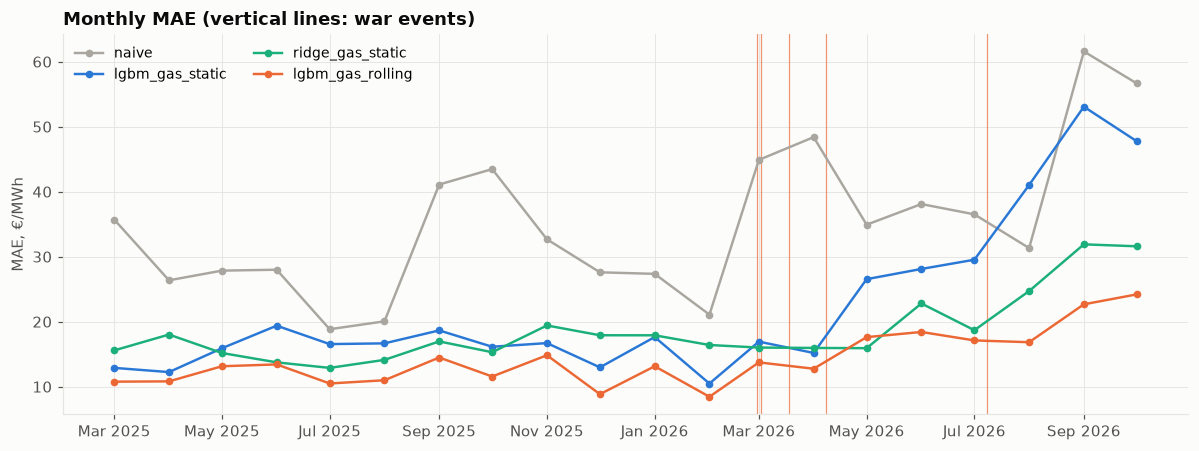

In [5]:
p = pred.copy()
p["month"] = p["delivery_date"].dt.to_period("M").dt.to_timestamp()
monthly = p.groupby("month").apply(lambda g: pd.Series({m: (g["price"] - g[m]).abs().mean() for m in show}))
fig, ax = plt.subplots()
for m in show:
    ax.plot(monthly.index, monthly[m], color=colors[m], marker="o", markersize=4, label=m)
plots.mark_events(ax, label=False)
ax.set_ylabel("MAE, €/MWh"); ax.set_title("Monthly MAE (vertical lines: war events)")
ax.legend(loc="upper left", ncol=2)
plots.date_axis(ax)
fig.tight_layout(); save(fig, "08_monthly_mae")

## 3. Why the static model fails: bias, not noise

Mean error (actual − forecast) > 0 means the model **under-forecasts**. Two things happen at once:

* **Trees cannot extrapolate.** LightGBM cannot predict outside the range of targets it saw in training; when gas moved
  to levels with no recent precedent, it kept forecasting "pre-war" prices (bias up to +50 €/MWh).
* **The relationship itself changed.** The linear model *can* extrapolate, yet its bias also grows (to about +25 €/MWh by
  October): the supply curve moved up by more than the pre-war gas coefficient implies. Only retraining catches that.

,lgbm_gas_static,ridge_gas_static,lgbm_gas_rolling
month,,,
2026-03-01,13.5,5.4,6.8
2026-04-01,7.5,-4.2,-0.6
2026-05-01,23.3,7.8,12.0
2026-06-01,27.0,15.4,11.4
2026-07-01,28.9,12.2,8.2
2026-08-01,40.9,21.0,12.2
2026-09-01,52.5,18.9,8.5
2026-10-01,46.4,25.5,2.7


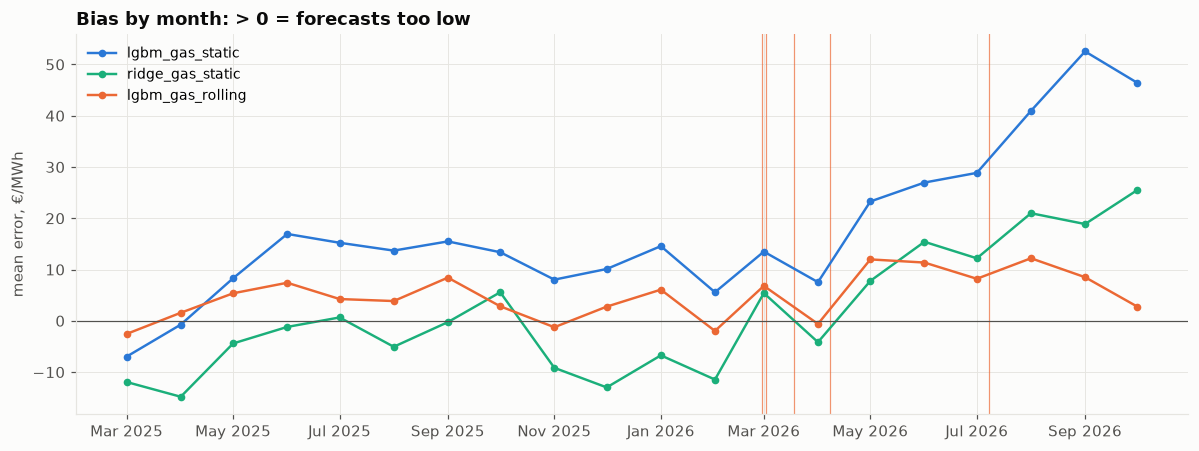

In [6]:
bias = p.groupby("month").apply(lambda g: pd.Series({m: (g["price"] - g[m]).mean() for m in show[1:]}))
fig, ax = plt.subplots()
for m in show[1:]:
    ax.plot(bias.index, bias[m], color=colors[m], marker="o", markersize=4, label=m)
ax.axhline(0, color=INK_2, linewidth=0.8)
plots.mark_events(ax, label=False)
ax.set_ylabel("mean error, €/MWh"); ax.set_title("Bias by month: > 0 = forecasts too low")
ax.legend(loc="upper left")
plots.date_axis(ax)
fig.tight_layout(); save(fig, "09_bias")
bias.loc["2026-03":].round(1)

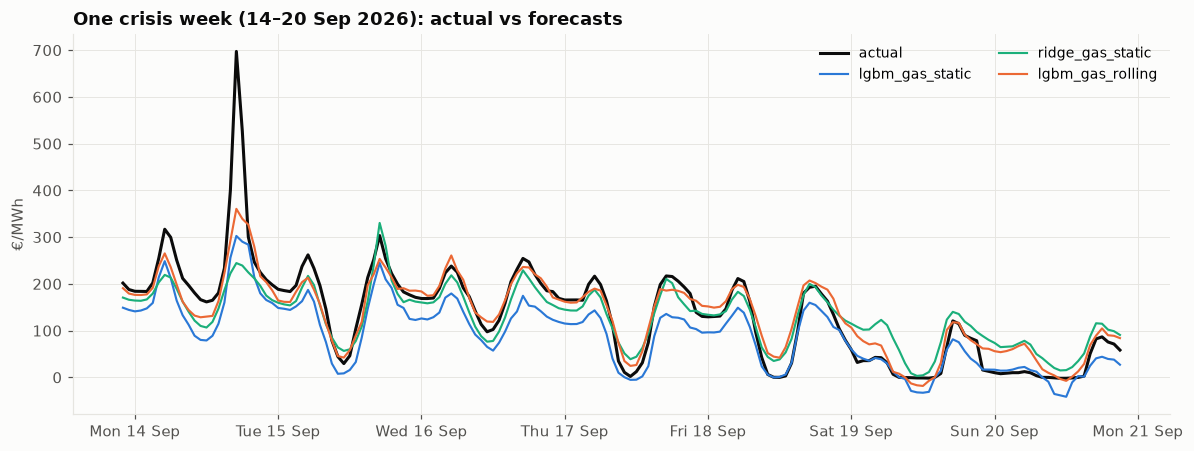

In [7]:
week = p[(p["delivery_date"] >= "2026-09-14") & (p["delivery_date"] <= "2026-09-20")]
fig, ax = plt.subplots()
ax.plot(week.index, week["price"], color="#0b0b0b", linewidth=2, label="actual")
for m in show[1:]:
    ax.plot(week.index, week[m], color=colors[m], linewidth=1.4, label=m)
ax.set_ylabel("€/MWh"); ax.set_title("One crisis week (14–20 Sep 2026): actual vs forecasts")
ax.legend(loc="upper right", ncol=2)
plots.date_axis(ax, "%a %d %b")
fig.tight_layout(); save(fig, "10_sample_week")

## 4. What is a forecast worth? 1 MW / 1 MWh battery

One charge/discharge cycle per day, hours picked from the **forecast**, revenue settled at **actual** prices,
round-trip efficiency 88 %. Benchmark: the same strategy with perfect knowledge of prices.

In [8]:
b = battery.pivot(index="model", columns="period", values=["capture_rate", "revenue_per_day"])
b.columns = [f"{a} · {p}" for a, p in b.columns]
b.sort_values("capture_rate · crisis", ascending=False).round(3)

,capture_rate · crisis,capture_rate · normal,revenue_per_day · crisis,revenue_per_day · normal
model,,,,
ridge_gas_static,0.987,0.949,153.703,94.449
ridge_base_rolling,0.986,0.951,153.543,94.648
ridge_gas_rolling,0.986,0.950,153.573,94.526
ridge_base_static,0.986,0.950,153.579,94.563
lgbm_base_rolling,0.976,0.942,151.976,93.824
lgbm_gas_static,0.976,0.938,151.985,93.426
lgbm_gas_rolling,0.976,0.945,152.043,94.035
lgbm_base_static,0.971,0.939,151.146,93.446
naive,0.918,0.820,142.917,81.602


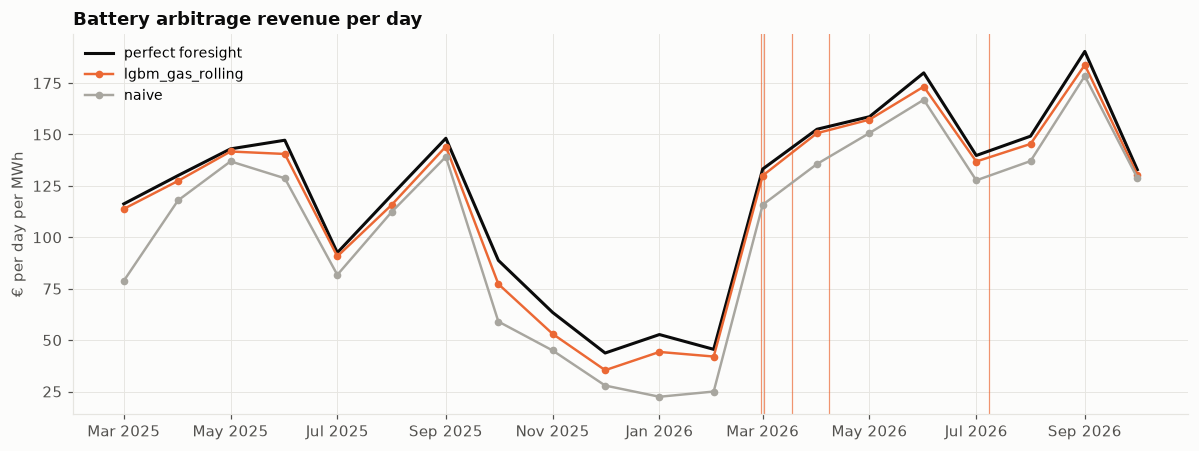

In [9]:
bd = pd.read_parquet(PROCESSED_DIR / "battery_daily.parquet")
bd = bd[bd["model"].isin(["naive", "lgbm_gas_rolling"])]
bd["month"] = pd.to_datetime(bd["date"]).dt.to_period("M").dt.to_timestamp()
rev = bd.groupby(["month", "model"])["revenue"].mean().unstack()
perfect = bd[bd["model"] == "naive"].groupby("month")["perfect"].mean()
fig, ax = plt.subplots()
ax.plot(perfect.index, perfect, color="#0b0b0b", linewidth=2, label="perfect foresight")
ax.plot(rev.index, rev["lgbm_gas_rolling"], color=CRISIS, marker="o", markersize=4, label="lgbm_gas_rolling")
ax.plot(rev.index, rev["naive"], color=MUTED, marker="o", markersize=4, label="naive")
plots.mark_events(ax, label=False)
ax.set_ylabel("€ per day per MWh"); ax.set_title("Battery arbitrage revenue per day")
ax.legend(loc="upper left")
plots.date_axis(ax)
fig.tight_layout(); save(fig, "11_battery_revenue")

Battery revenue is strongly seasonal (small spreads in winter), so the crisis is compared with **the same calendar
window of 2025**, not with the whole normal year:

In [10]:
bd_all = pd.read_parquet(PROCESSED_DIR / "battery_daily.parquet")
bd_all["date"] = pd.to_datetime(bd_all["date"])
last = bd_all["date"].max()
windows = {"same window 2025": bd_all["date"].between(pd.Timestamp("2025-02-28"), last - pd.DateOffset(years=1)),
           "crisis 2026": bd_all["date"] >= pd.Timestamp("2026-02-28")}
rows = []
for name, mask in windows.items():
    for m, g in bd_all[mask].groupby("model"):
        rows.append({"window": name, "model": m, "revenue €/day": g["revenue"].mean(),
                     "perfect €/day": g["perfect"].mean(), "capture": g["revenue"].sum() / g["perfect"].sum()})
same = pd.DataFrame(rows)
same.pivot(index="model", columns="window", values=["revenue €/day", "capture"]).round(3)     .sort_values(("revenue €/day", "crisis 2026"), ascending=False)

revenue €/day                      capture                 
window               crisis 2026 same window 2025 crisis 2026 same window 2025
model                                                                         
ridge_gas_static         153.703          122.110       0.987            0.968
ridge_base_static        153.579          122.163       0.986            0.969
ridge_gas_rolling        153.573          122.185       0.986            0.969
ridge_base_rolling       153.543          122.271       0.986            0.970
lgbm_gas_rolling         152.043          122.097       0.976            0.968
lgbm_gas_static          151.985          121.184       0.976            0.961
lgbm_base_rolling        151.976          121.759       0.976            0.966
lgbm_base_static         151.146          121.148       0.971            0.961
naive                    142.917          110.896       0.918            0.879

Is the revenue difference between models real? Same Diebold–Mariano test, with daily revenue as the (negative) loss:

In [11]:
from src.dm_test import dm_pvalue
rows = []
for period in ["normal", "crisis"]:
    g = bd_all[bd_all["period"] == period]
    loss = {m: -s.set_index("date")["revenue"] for m, s in g.groupby("model")}
    for a, b in [("lgbm_gas_rolling", "naive"), ("ridge_gas_static", "naive"),
                 ("lgbm_gas_rolling", "lgbm_gas_static"), ("ridge_gas_static", "lgbm_gas_rolling")]:
        rows.append({"period": period, "A": a, "B": b, "A − B, €/day": (loss[b] - loss[a]).mean(),
                     "p-value (A earns more)": dm_pvalue(loss[a], loss[b])})
pd.DataFrame(rows).round(3)

,period,A,B,"A − B, €/day",p-value (A earns more)
0,normal,lgbm_gas_rolling,naive,12.433,0.000
1,normal,ridge_gas_static,naive,12.847,0.000
2,normal,lgbm_gas_rolling,lgbm_gas_static,0.609,0.078
3,normal,ridge_gas_static,lgbm_gas_rolling,0.414,0.172
4,crisis,lgbm_gas_rolling,naive,9.126,0.000
5,crisis,ridge_gas_static,naive,10.786,0.000
6,crisis,lgbm_gas_rolling,lgbm_gas_static,0.058,0.449
7,crisis,ridge_gas_static,lgbm_gas_rolling,1.659,0.005


## Takeaways (as of 13 Oct 2026)

1. **Accuracy.** In a normal year LightGBM beats the naive benchmark by ~60 % (MAE 11.8 vs 29.2 €/MWh).
2. **The war broke the frozen model.** Trained before the window and left alone, LightGBM's MAE jumped to ~31 €/MWh
   (×2.3) — with or without gas features (30.9 vs 31.0, not significantly different). Trees cannot extrapolate beyond
   the gas levels seen in training, and the price–gas relationship itself shifted (the linear model's bias also grows).
   **Weekly retraining with gas features** keeps the error at 17.4, significantly better than every other variant
   (DM test, p < 0.01).
3. **Gas features need retraining to help.** In the normal year the static LightGBM got *worse* with gas features
   (15.6 vs 13.7, bias +9.5 €/MWh). Price lags already carry the gas level, and the tree used TTF as a proxy for
   season: TTF of 25–30 €/MWh came with an average price of 64 €/MWh in training (mostly spring/summer 2024)
   but 95 €/MWh in the test year (winter 2025/26). Dropping 2023 from training does not fix it (16.8).
4. **MAE is the wrong metric for a battery.** One cycle a day only needs the *shape* of the day. Every real model
   earns ~9–11 €/day more than the naive one in the crisis (≈ 3.3–3.9 k€ per MW per year, p < 0.001), but between real
   models the differences are cents to ~2 €/day: weekly retraining adds 0.06 €/day (not significant), and the linear
   models earn slightly but significantly more than LightGBM (+1.7 €/day, p = 0.005) despite a worse MAE.
5. **The crisis made flexibility more valuable**: on the same calendar window, perfect-foresight battery revenue rose
   from ~126 to ~156 € per day per MWh (+23 %), because gas raised evening peaks much more than midday prices.